# Experiment 15 — Explore where Layer 1 has significant residuals

This notebook reconstructs the chronological OOF residuals from the saved Exp 14 Layer 1 AutoGluon models. It studies residual direction, magnitude, tails, time drift, categorical segments, and which original features best explain absolute error. No AutoGluon model is retrained.

**Executed findings:** across **86,423** chronological OOF rows, RMSE was **612.475** and mean residual (`actual − prediction`) was **+217.05 SGD**, showing underforecasting in these expanding folds. Median absolute residual was **381.31**, the 90th percentile **1,023.83**, and **10.76%** of rows had absolute error at least 1,000. Error was heterogeneous: executive flats scored **720.34 RMSE**, 5-room **653.38**, and 3-room **542.44**. This motivated specialist residual models but also showed that the difficult tail is broad and hard to identify prospectively.

In [1]:
from pathlib import Path
import json,os,sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from autogluon.tabular import TabularPredictor
from lightgbm import LGBMRegressor
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
configured_root=os.environ.get('KDDM_PROJECT_ROOT')
roots=([Path(configured_root)] if configured_root else [])+[Path.cwd(),*Path.cwd().parents]
project_root=next((root for root in roots if (root/'exploration/metul/preprocessing.py').exists()),None)
if project_root is None:raise FileNotFoundError('Set KDDM_PROJECT_ROOT to the project directory.')
sys.path.insert(0,str(project_root/'exploration'/'metul'))
from preprocessing import RentalPreprocessor,load_datasets
TARGET='MONTHLY_RENT';N_SPLITS=3;RANDOM_STATE=42
source_nb=json.loads((project_root/'exploration'/'metul'/'exp_14_resale_features_lgbm.ipynb').read_text())
source_cells={cell.get('metadata',{}).get('id'):''.join(cell.get('source',[])) for cell in source_nb['cells']}
exec(source_cells['setup'],globals());exec(source_cells['exp9-best-feature-transformer'],globals())
model_root=project_root/'exploration'/'metul'/'ag_exp_14_ag_residual_models'
requested_run=os.environ.get('EXP15_SOURCE_RUN_ID')
if requested_run: run_dir=model_root/requested_run
else:
    candidates=sorted(path for path in model_root.iterdir() if (path/'layer1_oof_3').exists())
    if not candidates:raise FileNotFoundError('No completed Exp 14 Layer 1 OOF run found.')
    run_dir=candidates[-1]
print(f'Using saved Exp 14 run: {run_dir.name}')


Using saved Exp 14 run: 20261015_144824


In [2]:
_,datasets=load_datasets(project_root/'data')
raw=datasets['train'].copy();raw['period']=pd.to_datetime(raw['RENT_APPROVAL_DATE']+'-01').dt.to_period('M')
periods=np.sort(raw.period.unique());cutoff=periods[int(len(periods)*.80)];raw_fit=raw.loc[raw.period<cutoff].copy()
def best_features(history,future):
    processor=RentalPreprocessor(datasets)
    history_base=processor.fit_transform(history.drop(columns=['period',TARGET],errors='ignore'))
    future_base=processor.transform(future.drop(columns=['period',TARGET],errors='ignore'))
    return make_exp9_best_features(history,future,history_base,future_base)
fit_periods=np.sort(raw_fit.period.unique());parts=[]
for fold,(early_index,later_index) in enumerate(TimeSeriesSplit(n_splits=N_SPLITS).split(fit_periods),1):
    early=raw_fit.loc[raw_fit.period.isin(fit_periods[early_index])].copy();later=raw_fit.loc[raw_fit.period.isin(fit_periods[later_index])].copy()
    _,later_x=best_features(early,later);predictor=TabularPredictor.load(str(run_dir/f'layer1_oof_{fold}'))
    prediction=predictor.predict(later_x).astype(float).to_numpy()
    part=later_x.copy();part['period']=later.period.to_numpy();part['actual']=later[TARGET].to_numpy();part['prediction']=prediction;part['residual']=part.actual-part.prediction;part['absolute_residual']=part.residual.abs();part['squared_residual']=part.residual.pow(2);part['fold']=fold
    parts.append(part);print(f'Fold {fold}: {len(part):,} residuals')
residuals=pd.concat(parts,ignore_index=True)
print(f'OOF RMSE: {mean_squared_error(residuals.actual,residuals.prediction)**.5:.3f}; positive residual = underforecast')
display(residuals[['actual','prediction','residual','absolute_residual']].describe(percentiles=[.5,.75,.8,.9,.95,.975,.99]))


[categorical_clean] HDB lookup | TOWN: 26 -> 26 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | BLOCK: 2735 -> 2735 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | STREET: 576 -> 576 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | POSTAL_CODE: 9180 -> 9180 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | SUBZONE: 156 -> 156 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces
[categorical_clean] HDB lookup | PLANNING_AREA: 31 -> 31 unique values | lowercase, trim, collapse whitespace, and replace hyphen/underscore/slash separators with spaces


,actual,prediction,residual,absolute_residual
count,86423.000000,86423.000000,86423.000000,86423.000000
mean,2791.240549,2574.190545,217.050004,475.623376
std,743.320096,515.285128,572.729411,385.888603
min,300.000000,1289.968140,-3873.494629,0.021484
50%,2800.000000,2512.872559,201.413574,381.314941
75%,3300.000000,2912.936890,584.700317,691.701416
80%,3500.000000,3015.872266,686.237549,783.380615
90%,3800.000000,3252.740039,956.008350,1023.826416
95%,4000.000000,3473.056763,1155.674243,1218.951807
97.5%,4300.000000,3706.433838,1330.055005,1390.189783


,absolute_residual_threshold
0.500,381.314941
0.750,691.701416
0.800,783.380615
0.900,1023.826416
0.950,1218.951807
0.975,1390.189783
0.990,1622.348169


,absolute_residual_threshold,rows,fraction
0,250,56012,0.648115
1,500,33629,0.389121
2,750,18791,0.217431
3,1000,9298,0.107587
4,1500,1365,0.015794


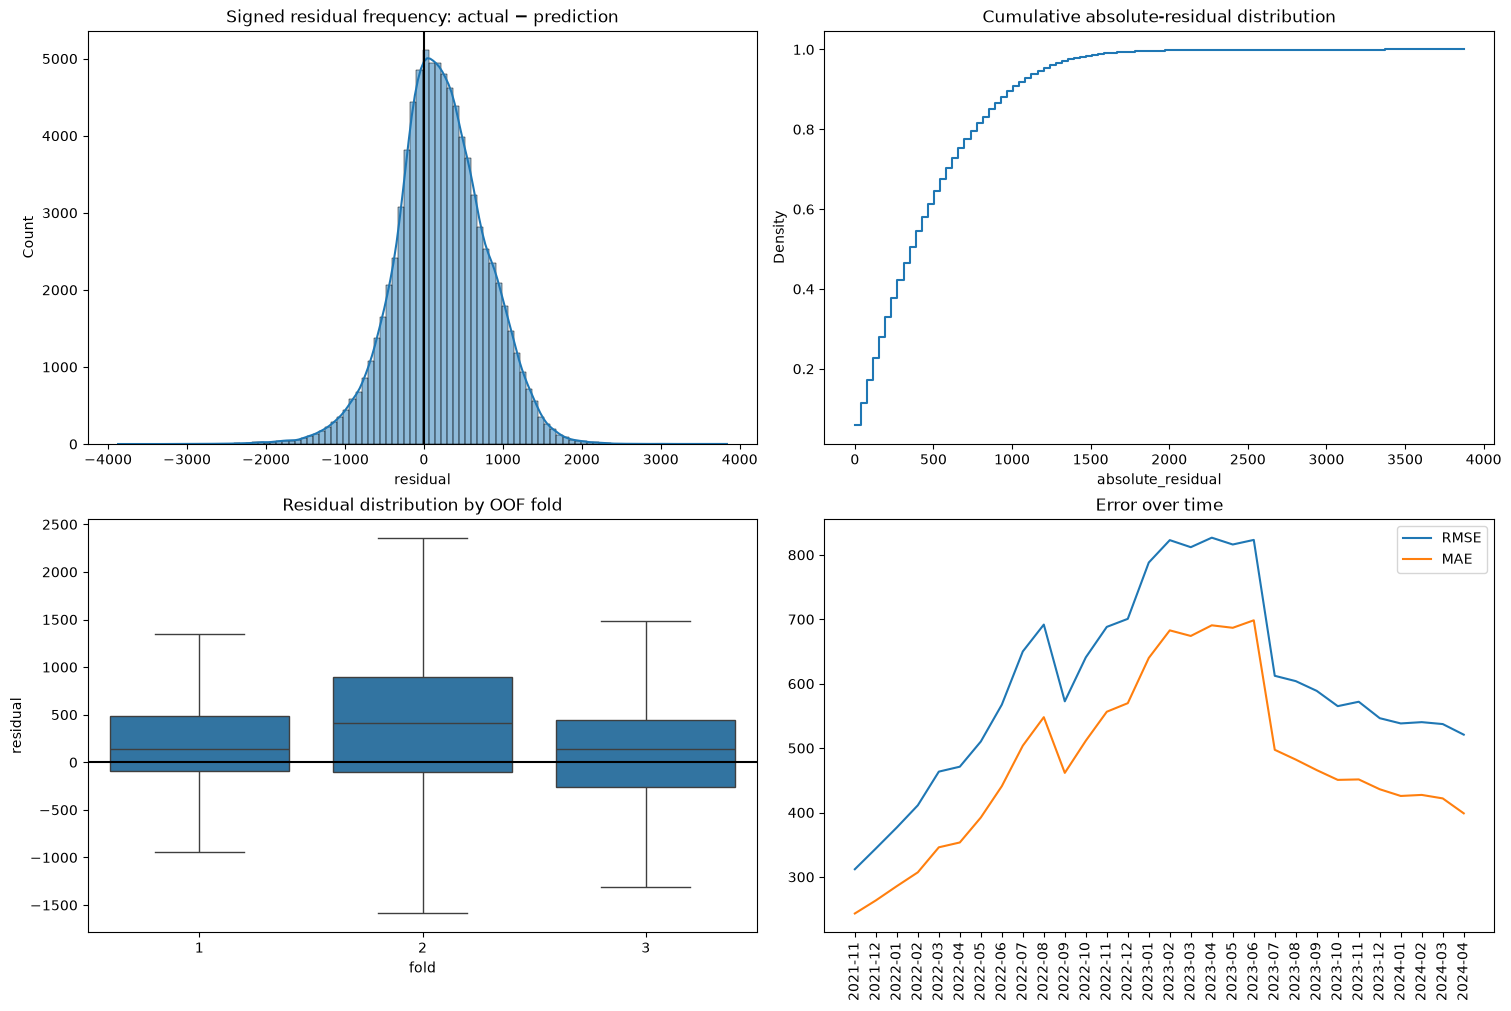

In [3]:
quantiles=residuals.absolute_residual.quantile([.50,.75,.80,.90,.95,.975,.99]).rename('absolute_residual_threshold').to_frame()
display(quantiles)
fixed_thresholds=[250,500,750,1000,1500]
threshold_frequency=pd.DataFrame({'absolute_residual_threshold':fixed_thresholds,'rows':[residuals.absolute_residual.ge(value).sum() for value in fixed_thresholds],'fraction':[residuals.absolute_residual.ge(value).mean() for value in fixed_thresholds]})
display(threshold_frequency)
fig,axes=plt.subplots(2,2,figsize=(15,10),constrained_layout=True)
sns.histplot(residuals.residual,bins=100,kde=True,ax=axes[0,0]);axes[0,0].axvline(0,color='black');axes[0,0].set_title('Signed residual frequency: actual − prediction')
sns.histplot(residuals.absolute_residual,bins=100,cumulative=True,stat='density',element='step',fill=False,ax=axes[0,1]);axes[0,1].set_title('Cumulative absolute-residual distribution')
sns.boxplot(data=residuals,x='fold',y='residual',showfliers=False,ax=axes[1,0]);axes[1,0].axhline(0,color='black');axes[1,0].set_title('Residual distribution by OOF fold')
monthly=residuals.groupby('period').agg(RMSE=('squared_residual',lambda values:np.sqrt(values.mean())),MAE=('absolute_residual','mean'),bias=('residual','mean'),rows=('residual','size')).reset_index();monthly['period_label']=monthly.period.astype(str)
axes[1,1].plot(monthly.period_label,monthly.RMSE,label='RMSE');axes[1,1].plot(monthly.period_label,monthly.MAE,label='MAE');axes[1,1].tick_params(axis='x',rotation=90);axes[1,1].legend();axes[1,1].set_title('Error over time')
plt.show()


In [4]:
SIGNIFICANT_QUANTILE=.90
significant_threshold=float(residuals.absolute_residual.quantile(SIGNIFICANT_QUANTILE));residuals['significant_residual']=residuals.absolute_residual.ge(significant_threshold)
print(f'Significant = top {100*(1-SIGNIFICANT_QUANTILE):.0f}% absolute residuals: >= ${significant_threshold:,.2f}')
def segment_errors(column,min_rows=100):
    summary=residuals.groupby(column,dropna=False).agg(rows=('residual','size'),RMSE=('squared_residual',lambda values:np.sqrt(values.mean())),MAE=('absolute_residual','mean'),bias=('residual','mean'),significant_rate=('significant_residual','mean')).reset_index()
    return summary.loc[summary.rows>=min_rows].sort_values(['significant_rate','RMSE'],ascending=False)
for column,min_rows in [('TOWN',250),('FLAT_TYPE',250),('FLAT_MODEL',150),('nearest_mrt_name',100),('STREET',100),('BLOCK',50)]:
    print(f'Highest-error groups for {column}')
    display(segment_errors(column,min_rows).head(15))


Significant = top 10% absolute residuals: >= $1,023.83
Highest-error groups for TOWN


,TOWN,rows,RMSE,MAE,bias,significant_rate
6,bukit timah,256,807.363581,622.713446,280.060642,0.179688
16,pasir ris,2351,642.426104,496.687588,243.215104,0.126755
2,bishan,1895,665.361617,513.951608,239.864967,0.125594
7,central,1354,675.181339,499.748461,240.609073,0.118907
13,jurong west,5996,639.306572,504.478691,190.852337,0.117745
4,bukit merah,4731,651.665539,491.370110,227.636047,0.114141
17,punggol,3869,607.848693,472.531745,238.094720,0.107521
18,queenstown,3491,622.748972,475.418974,247.906064,0.107133
22,tampines,5787,616.981794,479.730603,229.130391,0.105754
21,serangoon,1948,615.966725,472.577946,193.155797,0.103696


Highest-error groups for FLAT_TYPE


,FLAT_TYPE,rows,RMSE,MAE,bias,significant_rate
5,executive,4675,720.336394,558.389177,288.241122,0.160642
4,5 room,20469,653.382544,506.341428,261.662051,0.124481
3,4 room,31148,628.698645,490.271029,221.210220,0.112367
1,2 room,1791,582.231557,463.019526,154.332751,0.073702
2,3 room,28313,542.444406,424.520842,172.695454,0.060432


Highest-error groups for FLAT_MODEL


...

,nearest_mrt_name,rows,RMSE,MAE,bias,significant_rate
6,beauty world mrt station,141,859.510185,675.517297,246.402043,0.226950
70,labrador park mrt station,108,783.346516,591.454983,332.336209,0.194444
89,outram park mrt station,314,836.501773,622.271846,406.254190,0.187898
53,havelock mrt station,356,876.469881,636.181561,342.479953,0.179775
42,dover mrt station,365,715.479878,546.017062,229.083847,0.156164
49,gek poh mrt station,474,667.578339,524.559817,170.552628,0.147679
10,bedok south mrt station,119,654.221002,510.258680,175.340266,0.142857
114,tanjong pagar mrt station,304,723.198909,513.320579,295.883004,0.141447
60,jurong lake district mrt station,248,649.050109,500.719710,217.708285,0.137097
111,tampines north mrt station,307,650.088411,510.563577,299.670339,0.136808


Highest-error groups for STREET


,STREET,rows,RMSE,MAE,bias,significant_rate
194,ghim moh link,157,900.551466,730.068121,312.118463,0.286624
138,clementi avenue 1,129,840.851521,680.544379,283.363382,0.248062
352,pasir ris street 53,106,774.743364,620.561807,375.495861,0.235849
107,cantonment road,291,912.166377,679.543973,513.711370,0.233677
489,toh yi drive,141,859.510185,675.517297,246.402043,0.226950
481,telok blangah street 31,124,817.933937,635.618398,465.397282,0.225806
168,depot road,140,782.643818,583.598767,321.742179,0.200000
166,dawson road,150,774.837221,597.419530,299.853494,0.200000
61,boon keng road,128,703.126563,559.680803,305.196280,0.187500
344,pasir ris drive 6,261,680.360284,518.474668,227.751537,0.183908


Highest-error groups for BLOCK


,BLOCK,rows,RMSE,MAE,bias,significant_rate
1294,457,57,902.867746,674.048661,389.861367,0.263158
1022,359,52,815.509481,677.268794,257.043842,0.230769
373,1c,52,882.738933,670.479093,356.766888,0.211538
1931,662,66,789.210633,626.777427,136.616775,0.196970
2295,805,58,650.753288,473.473041,292.097536,0.189655
1570,523,107,659.933138,501.663671,243.778561,0.186916
2661,99,62,739.058357,512.708028,29.145047,0.177419
1212,436,51,697.237536,564.811016,249.345114,0.176471
1124,408,109,708.308604,580.402283,320.540395,0.174312
982,348,75,647.092106,516.410745,270.800397,0.173333


,feature,spearman_with_abs_residual,spearman_with_signed_residual
3,coe_quota_premium_mean,0.238791,0.077575
1,approval_date_num,0.136997,-0.019654
9,town_flat_type_target_mean,0.089594,-0.006822
0,FLOOR_AREA_SQM,0.074355,0.061909
4,YEAR_COMPLETED,0.041218,0.046058
8,monthly_target_lag,-0.027503,-0.153660
5,MAX_FLOOR,0.022474,0.031835
2,approval_month,-0.017774,-0.076759
7,mall_dist_nearest_km,0.000631,-0.010200
6,mrt_dist_nearest_km,-0.000058,0.001288


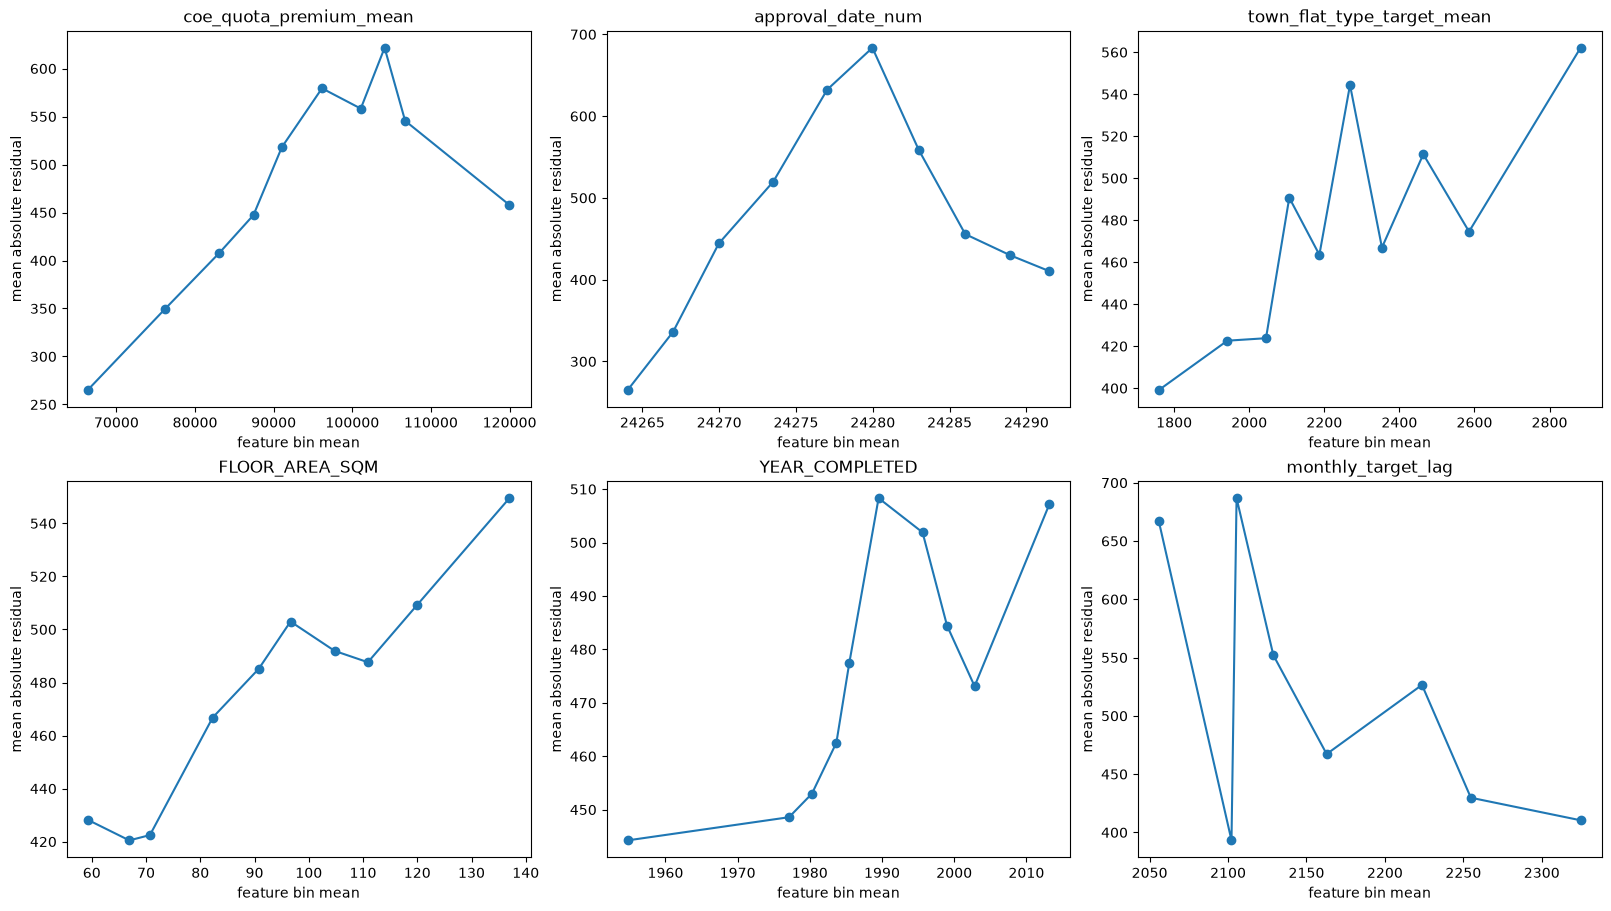

In [5]:
numeric_columns=residuals[BEST_FEATURES].select_dtypes(include=np.number).columns.tolist()
numeric_association=pd.DataFrame({'feature':numeric_columns,'spearman_with_abs_residual':[residuals[column].corr(residuals.absolute_residual,method='spearman') for column in numeric_columns],'spearman_with_signed_residual':[residuals[column].corr(residuals.residual,method='spearman') for column in numeric_columns]})
display(numeric_association.reindex(numeric_association.spearman_with_abs_residual.abs().sort_values(ascending=False).index))
top_numeric=numeric_association.spearman_with_abs_residual.abs().nlargest(6).index
fig,axes=plt.subplots(2,3,figsize=(16,9),constrained_layout=True)
for axis,row_index in zip(axes.ravel(),top_numeric):
    feature=numeric_association.loc[row_index,'feature'];bins=pd.qcut(residuals[feature],q=10,duplicates='drop');binned=residuals.groupby(bins,observed=True).agg(feature_mean=(feature,'mean'),mean_absolute_residual=('absolute_residual','mean'))
    axis.plot(binned.feature_mean,binned.mean_absolute_residual,marker='o');axis.set(title=feature,xlabel='feature bin mean',ylabel='mean absolute residual')
plt.show()


,feature,RMSE_increase_when_shuffled,std
5,FLOOR_AREA_SQM,9.595843,0.294692
9,YEAR_COMPLETED,7.929780,0.091471
3,FLAT_TYPE,2.176625,0.023754
4,FLAT_MODEL,1.339359,0.089191
15,nearest_mrt_name,1.086615,0.067882
8,coe_quota_premium_mean,0.639760,0.084906
16,nearest_tourist_attraction_name,0.582658,0.059623
7,approval_month,0.366440,0.064315
13,monthly_target_lag,0.008807,0.013881
6,approval_date_num,0.000000,0.000000


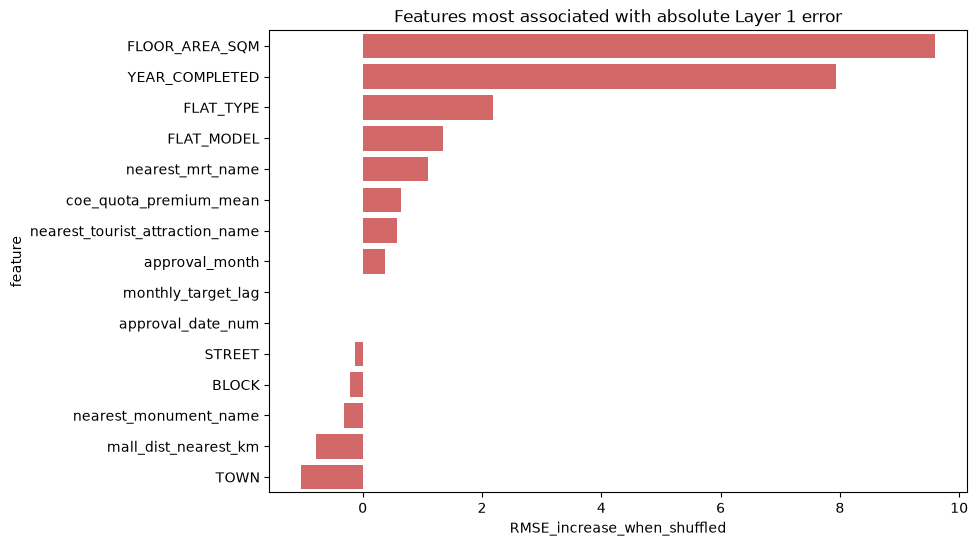

In [6]:
# Fit an interpretable diagnostic model on earlier OOF folds and measure which original features explain absolute error on the latest fold.
x=residuals[BEST_FEATURES];y=residuals.absolute_residual
train_mask=residuals.fold<residuals.fold.max();test_mask=~train_mask
categorical=x.select_dtypes(include=['object','category','string']).columns.tolist();numeric=[column for column in BEST_FEATURES if column not in categorical]
processor=ColumnTransformer([('numeric',Pipeline([('impute',SimpleImputer(strategy='median'))]),numeric),('categorical',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('ordinal',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1))]),categorical)])
error_model=Pipeline([('encode',processor),('model',LGBMRegressor(n_estimators=500,learning_rate=.04,num_leaves=31,random_state=RANDOM_STATE,n_jobs=-1,verbosity=-1))])
error_model.fit(x.loc[train_mask],y.loc[train_mask])
importance=permutation_importance(error_model,x.loc[test_mask],y.loc[test_mask],scoring='neg_root_mean_squared_error',n_repeats=3,random_state=RANDOM_STATE,n_jobs=-1)
feature_importance=pd.DataFrame({'feature':BEST_FEATURES,'RMSE_increase_when_shuffled':importance.importances_mean,'std':importance.importances_std}).sort_values('RMSE_increase_when_shuffled',ascending=False)
display(feature_importance)
plt.figure(figsize=(9,6));sns.barplot(data=feature_importance.head(15),x='RMSE_increase_when_shuffled',y='feature',color='#e45756');plt.title('Features most associated with absolute Layer 1 error');plt.show()


## How to choose rows for the specialized residual model

Start with the top-10% absolute-residual threshold above. A deployable gate cannot know the true residual at prediction time, so Exp 15's next modelling step should train a classifier to predict `significant_residual` from the input features, then route only high-probability rows to a specialized residual model. Segment tables and permutation importance identify useful gating inputs.